# Experimental dendrite tomography

Reconstruct the bundled I12 dendritic-growth dataset using flat/dark correction, padded FBP, PWLS-TV and SWLS-TV. This replaces the legacy experimental walkthrough. It uses the archive and acquisition convention from `demos/experimental/dendrites_astra.py`, with settings adapted for a small interactive example.

The magnesium-alloy measurements were acquired at Diamond Light Source's I12 beamline. Experiment and reconstruction references are listed as Guo et al. (2018) and Kazantsev et al. (2017) in the [bibliography](../reference/bibliography.rst).

Requires the [ToMoBAR CUDA environment](../getting_started/installation.rst) and Matplotlib. **Data:** `tests/test_data/DendrRawData.npz` in the ToMoBAR repository (about 9 MB). The next cell uses a local checkout if available, otherwise downloads that archive. Saved outputs can be read without downloading data or accessing a GPU.

In [1]:
%matplotlib inline

from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import subprocess

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import tomobar

from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.options import DataFidelity, Regularisation
from tomobar.preprocessing import normaliser
from tomobar.reconstruction.direct import DirectReconstructor
from tomobar.reconstruction.iterative import IterativeReconstructor

print("Executed (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
for package in ("tomobar", "numpy", "cupy", "astra-toolbox", "matplotlib"):
    print(f"{package}: {version(package)}")
source_root = Path(tomobar.__file__).resolve().parent.parent
if (source_root / ".git").exists():
    print(
        "Checkout revision:",
        subprocess.check_output(
            ["git", "-C", str(source_root), "rev-parse", "--short", "HEAD"], text=True
        ).strip(),
        "(local edits may be present)",
    )
device_index = 0
name = cp.cuda.runtime.getDeviceProperties(device_index)["name"]
print("GPU:", name.decode() if isinstance(name, bytes) else name)
print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())

Executed (UTC): 2026-11-18T22:17:17+00:00
tomobar: 2026.4.0.0
numpy: 2.4.6
cupy: 14.2.0
astra-toolbox: 2.5.0
matplotlib: 3.11.1
Checkout revision: d170474 (local edits may be present)
GPU: NVIDIA GeForce RTX 4060
CUDA runtime: 13020


## 1. Locate and load the measurements

Open this notebook from the repository or download it and run in a writable directory. To use your own copy, set `data_path` explicitly. The archive stores raw counts, acquisition angle readings, one averaged flat and one averaged dark. Original array order is `(detX, angles, detY)`.

The archived angle readings are offset degree values, not radians. For consistency with the dendrites demo, we use its explicit 360-view half-turn convention, `np.linspace(0, np.pi, 360)`, and zero centre-of-rotation correction. These are example conventions rather than independently calibrated acquisition geometry.

In [2]:
from urllib.request import urlretrieve

relative_data = Path("tests/test_data/DendrRawData.npz")
candidates = [
    directory / relative_data for directory in (Path.cwd(), *Path.cwd().parents)
]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    data_path = Path.cwd() / "data" / "DendrRawData.npz"
    if not data_path.is_file():
        data_path.parent.mkdir(parents=True, exist_ok=True)
        data_url = "https://raw.githubusercontent.com/dkazanc/ToMoBAR/master/tests/test_data/DendrRawData.npz"
        print("Downloading the bundled dendrite archive (about 9 MB).")
        urlretrieve(data_url, data_path)

with np.load(data_path, allow_pickle=False) as archive:
    raw_full = archive["arr_0"]
    archived_angles = archive["arr_1"]
    flats_full = archive["arr_2"]
    darks_full = archive["arr_3"]
print("Raw shape (detX, angles, detY):", raw_full.shape)
print("Flat/dark shapes:", flats_full.shape, darks_full.shape)
print("Archived angle range:", archived_angles.min(), archived_angles.max())

Raw shape (detX, angles, detY): (1260, 360, 10)
Flat/dark shapes: (1260, 10) (1260, 10)
Archived angle range: 16740.453966106532 16919.961254242175


## 2. Select, downsample and normalise

We use **detector row 8**, matching the displayed row in the demo's `5:10` slab. Pairwise detector-column averaging reduces the width from 1260 to 630 before logarithmic normalisation. All 360 views are retained. Raw counts, flats and darks are averaged consistently; we do not average log-transformed data.

| Setting | Standalone demo | This notebook |
|---|---:|---:|
| Detector rows | 5–9 | 8 |
| Detector-column binning | 1 | 2 |
| Detector padding per side | 100 | 50 |
| Output width | 1000 | 500 |
| Centre correction | 0 | 0 |
| FISTA subsets / outer iterations | 6 / 20 | 6 / 20 |
| PD-TV strength / inner iterations | 0.1 / 50 | 0.1 / 50 |
| SWLS beta | 1 | 1 |

Padding and crop are scaled with binning; the regularisation settings are starting values borrowed from the demo, not a matched-resolution optimum. The grid is unit-spaced in **binned pixels**, so reconstructed values are per binned voxel and should not be directly compared with the unbinned demo's intensity scale.

Selected projections: (630, 360, 1)
Working volume: (1, 730, 730) Output: (1, 500, 500)


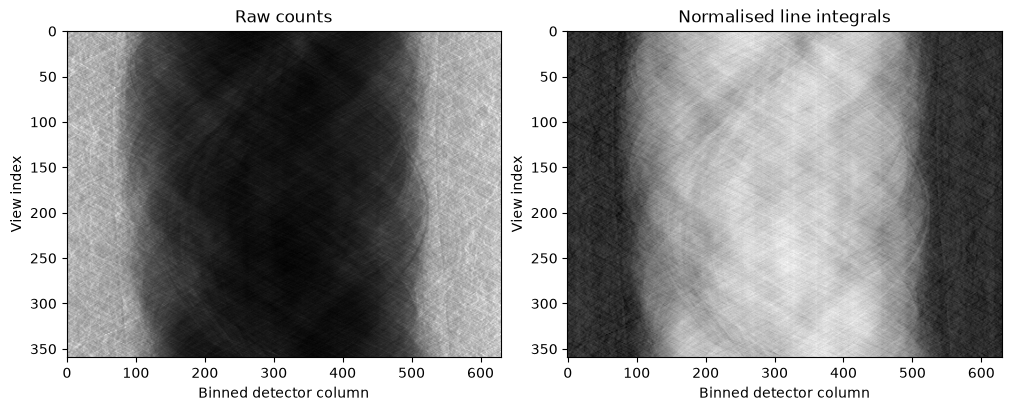

In [3]:
detector_row, binning = 8, 2
padding, output_width = 100 // binning, 1000 // binning


def bin_columns(array):
    array = np.asarray(array, dtype=np.float32)
    return array.reshape(array.shape[0] // binning, binning, *array.shape[1:]).mean(
        axis=1
    )


raw = bin_columns(raw_full[:, :, detector_row : detector_row + 1])
flats = bin_columns(flats_full[:, detector_row : detector_row + 1])[:, None, :]
darks = bin_columns(darks_full[:, detector_row : detector_row + 1])[:, None, :]
projections = np.asarray(
    normaliser(raw, flats, darks, log=True, method="mean", axis=1), dtype=np.float32
)
assert np.isfinite(projections).all()
input_axes = ("detX", "angles", "detY")
detector_width, view_count, detector_rows = projections.shape
scan = Parallel3DGeometry.tomography(
    angles=np.linspace(0, np.pi, view_count),
    detector_shape=(detector_rows, detector_width),
    centre_of_rotation=0.0,
)
working_width = detector_width + 2 * padding
working_grid = Volume3DGeometry(shape=(detector_rows, working_width, working_width))
output_shape = (detector_rows, output_width, output_width)
print("Selected projections:", projections.shape)
print("Working volume:", working_grid.shape, "Output:", output_shape)

figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, image, title in zip(
    axes,
    (raw[:, :, 0].T, projections[:, :, 0].T),
    ("Raw counts", "Normalised line integrals"),
):
    axis.imshow(image, cmap="gray", aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Binned detector column")
    axis.set_ylabel("View index")
plt.show()

## 3. Compare FBP with and without detector padding

The detector truncates the sample, so abrupt edges can cause boundary artefacts. Edge padding extends the measured detector values before filtering. It reduces some boundary effects but cannot recover unmeasured structure. Both results use the same central reconstruction field of view.

We use the demo's SINC filter with `cutoff_freq=1.1`. For this filter the cutoff is a shape parameter, not a fractional Nyquist frequency. See [FBP filtering](../howto/direct_reconstruction.rst).

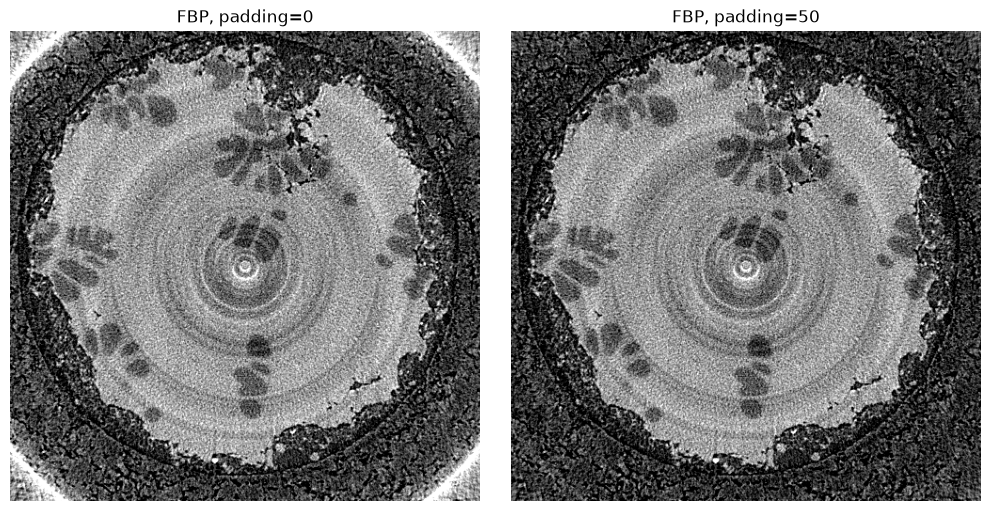

In [4]:
fbp_images = {}
for pad in (0, padding):
    with DirectReconstructor(
        projection_geometry=scan,
        volume_geometry=Volume3DGeometry(shape=output_shape),
        detector_padding=pad,
        device_index=device_index,
    ) as rec:
        fbp_images[f"FBP, padding={pad}"] = cp.asnumpy(
            rec.FBP(
                projections,
                input_axes=input_axes,
                filter_type="SINC",
                cutoff_freq=1.1,
                recon_mask_radius=None,
            )
        )

figure, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for axis, (label, image) in zip(axes, fbp_images.items()):
    axis.imshow(image[0], cmap="gray", vmin=0, vmax=0.006)
    axis.set_title(label)
    axis.set_axis_off()
plt.show()

## 4. Compare PWLS-TV and SWLS-TV

Raw counts provide approximate inverse-variance weights for the log-transformed data; the solver normalises them by their maximum. We use native PD-TV in float32. Each FISTA outer iteration visits six interleaved subsets. The demo's optional half-precision regulariser is omitted here for clarity.

SWLS targets stripe-like detector errors, whereas TV suppresses spatial variation in the reconstruction. Inspect full rings and thin dendritic features together: reducing rings alone does not establish a more accurate reconstruction. There is no ground-truth image for this experiment, so we do not report RMSE or declare one method universally best.

PWLS output shape: (1, 500, 500)


SWLS output shape: (1, 500, 500)


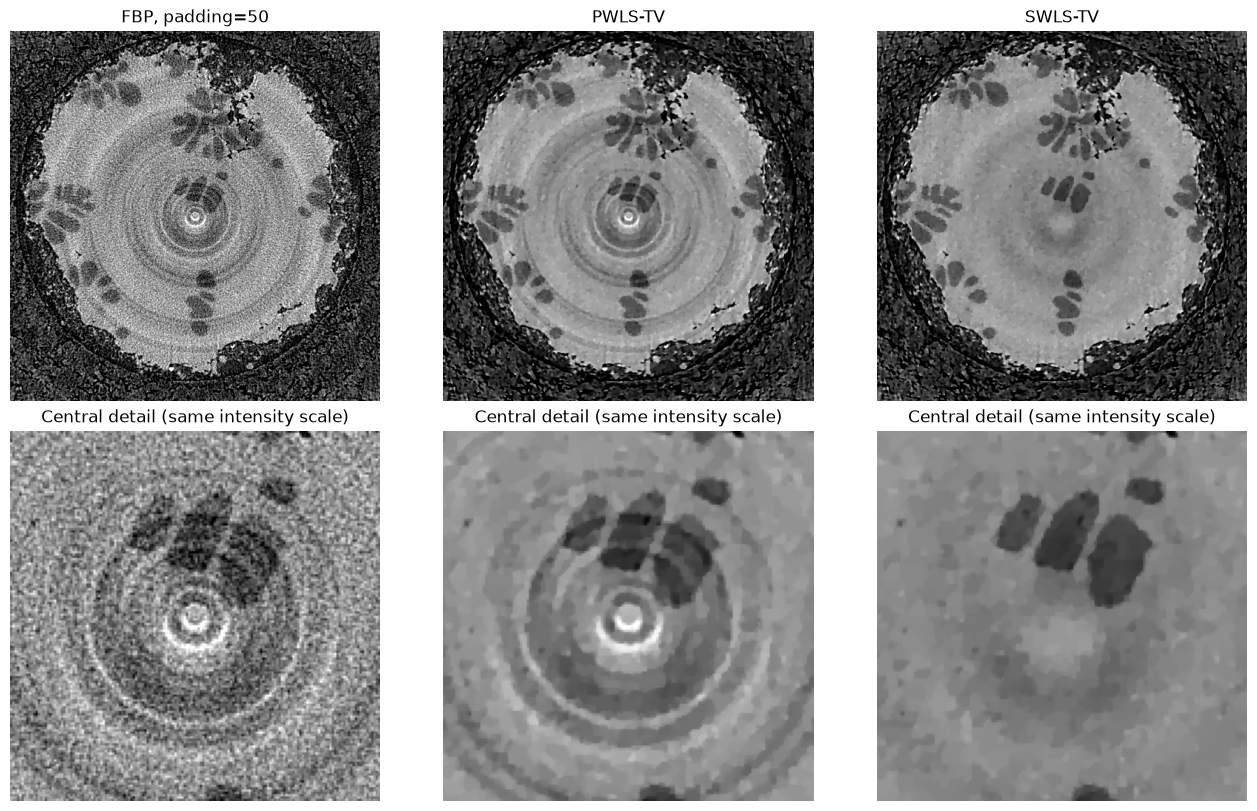

In [5]:
iterative_images = {}
with IterativeReconstructor(
    projection_geometry=scan,
    volume_geometry=working_grid,
    output_shape=output_shape,
    detector_padding=padding,
    num_subsets=6,
    device_index=device_index,
) as rec:
    lipschitz = rec.powermethod()
    tv = Regularisation(method="PD_TV", strength=0.1, iterations=50)
    for method in ("PWLS", "SWLS"):
        iterative_images[f"{method}-TV"] = cp.asnumpy(
            rec.FISTA(
                projections,
                input_axes=input_axes,
                weights=raw,
                fidelity=DataFidelity(method=method, beta_swls=1.0),
                regularisation=tv,
                lipschitz_constant=lipschitz,
                iterations=20,
                nonnegativity=True,
                recon_mask_radius=None,
            )
        )
        print(method, "output shape:", iterative_images[f"{method}-TV"].shape)

comparison = {
    f"FBP, padding={padding}": fbp_images[f"FBP, padding={padding}"],
    **iterative_images,
}
figure, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
for column, (label, image) in enumerate(comparison.items()):
    axes[0, column].imshow(image[0], cmap="gray", vmin=0, vmax=0.006)
    axes[0, column].set_title(label)
    axes[1, column].imshow(image[0, 170:330, 170:330], cmap="gray", vmin=0, vmax=0.006)
    axes[1, column].set_title("Central detail (same intensity scale)")
    for axis in axes[:, column]:
        axis.set_axis_off()
plt.show()

## Next steps

Try the full-resolution slab in `demos/experimental/dendrites_astra.py` for CGLS, Fourier inversion and ADMM comparisons. For this notebook, change TV strength or the SWLS parameter and inspect both fine features and artefacts. More iterations do not replace geometry calibration.

See [experimental datasets](../howto/experimental_data.rst), [padding and cropping](../howto/padding_cropping.rst), [solver configuration](../howto/configure_solvers.rst) and the [regularised synthetic comparison](regularised_reconstruction.ipynb).